In [104]:
# Summary statistics for speed-density correlation across beryl regions.
import pandas as pd
import glob
import os
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import torch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
# Path to the directory containing the CSV files
csv_dir = '../BerylFigures'
csv_files = glob.glob(os.path.join(csv_dir, 'results_*.csv'))

# List to store individual dataframes
dfs = []

for file in csv_files:
    try:
        df = pd.read_csv(file)
        dfs.append(df)
    except pd.errors.EmptyDataError:
        print(f"Skipping empty file: {file}")

# Concatenate all dataframes into one
combined_df = pd.concat(dfs, ignore_index=True)

# Display the first few rows and the shape of the combined dataframe
print(f"Combined DataFrame shape: {combined_df.shape}")
print(combined_df.head())

# Optional: Save the combined dataframe
# combined_df.to_csv('../BerylFigures/combined_beryl_results.csv', index=False)


Skipping empty file: ../BerylFigures/results_SPA.csv
Combined DataFrame shape: (256, 4)
  region  p_rotation  spearman_corr  n_neurons
0   PARN       0.000       0.786075       1349
1   MEPO       0.003       0.565408         28
2    PAA       0.027       0.332315        147
3    PVH       0.097       0.269841         55
4   VeCB       0.022       0.398379        353


In [105]:
.05/256

0.0001953125

In [106]:
combined_df = combined_df[combined_df['n_neurons'] >500]

In [107]:
.05/combined_df.shape[0]

0.0004065040650406504

/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


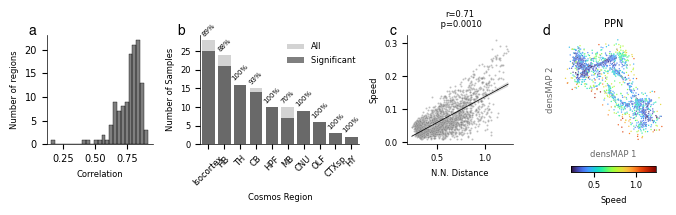

In [112]:
# Map Beryl regions to Cosmos regions
from iblatlas.regions import BrainRegions
br = BrainRegions()

# Mapping Beryl acronyms to Cosmos acronyms
combined_df['cosmos_region'] = br.acronym2acronym(combined_df['region'], mapping='Cosmos')

# Define significance
combined_df['is_significant'] = combined_df['p_rotation'] < .0004

# Calculate counts of total and significant results per Cosmos region
cosmos_summary = combined_df.groupby('cosmos_region')['is_significant'].agg(['count', 'sum']).reset_index()
cosmos_summary.columns = ['cosmos_region', 'total_count', 'significant_count']
cosmos_summary['fraction'] = cosmos_summary['significant_count'] / cosmos_summary['total_count']

# Sort by total count for better visualization (or significant_count)
cosmos_summary = cosmos_summary.sort_values('total_count', ascending=False)

import umap
import scipy.stats
from BWM.models.isometric_autoencoder import get_density_proxy
from BWM.bwm_functions import get_region_response_matrix

# Parameters for data loading
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

def iso_ae_preprocessing(pseudo_response_tensor):
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_pre_pca

def calculate_msd_data(response_tensor):
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    speed = np.median(np.abs(np.diff(z, axis=1)), axis=(0, 1))
    return speed

# Load example region data and compute projection/metrics
example_region = 'PPN'

# Get stats for example region
example_stats = combined_df[combined_df['region'] == example_region].iloc[0]
example_corr = example_stats['spearman_corr']
example_p = example_stats['p_rotation']
# pseudo_response_tensor, condition_matrix, neuron_eids = get_region_response_matrix(
#     eids=eids,
#     directory_path=directory_path,
#     region=example_region,
#     mapping='Beryl',
#     sigma=2,
#     n_steps=100,
#     threshold=1,
#     min_trials_per_condition=50,
#     n_pseudo=25,
#     conditions=['choice'],
#     event="stimOn_times",
#     filter_significant=True,
#     significance_threshold=0.
# )

X_example = iso_ae_preprocessing(pseudo_response_tensor)
msd_example = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))
density_example = get_density_proxy(X_example, k=50).numpy()

reducer = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors=min(500, X_example.shape[0]-1), random_state=42)
projection_example = reducer.fit_transform(X_example)

# Plotting
plt.rcParams.update({'font.size': 7})
fig, axes = plt.subplots(1, 4, figsize=(8, 1.5), gridspec_kw={'width_ratios': [1, 1.5, 1, 1], 'wspace': 0.4, 'bottom': 0.15})

# Add panel labels
for i, label in enumerate(['a', 'b', 'c', 'd']):
    axes[i].text(-0.1, 1.1, label, transform=axes[i].transAxes, fontsize=10, fontweight='bold', fontfamily='Helvetica', va='top', ha='right')

# Left subplot: Distribution of spearman_corr
sns.histplot(data=combined_df, x="spearman_corr", ax=axes[0], kde=False, color='k', bins=25, lw=1, alpha=.5)
axes[0].set_xlabel('Correlation', fontsize=6)
axes[0].set_ylabel('Number of regions', fontsize=6)

# Second subplot: Cosmos region counts
sns.barplot(data=cosmos_summary, x='cosmos_region', y='total_count', color='lightgrey', label='All', ax=axes[1])
sns.barplot(data=cosmos_summary, x='cosmos_region', y='significant_count', color='k', label='Significant ', ax=axes[1], alpha=.5)

for i, row in enumerate(cosmos_summary.itertuples()):
    axes[1].text(i, row.total_count + 1, f"{row.fraction*100:.0f}%", ha='center', fontsize=5, rotation=45)

axes[1].set_ylabel('Number of Samples', fontsize=6)
axes[1].set_xlabel('Cosmos Region', fontsize=6)
axes[1].tick_params(axis='x', rotation=45, labelsize=6)
axes[1].tick_params(axis='y', labelsize=6)
axes[1].legend(fontsize=6, loc='upper left', bbox_to_anchor=(0.5, 1), frameon=False)

# Third subplot: MSD vs Density scatter plot
sns.scatterplot(x=density_example, y=msd_example, color='gray', s=2, alpha=0.5, ax=axes[2])
sns.regplot(x=density_example, y=msd_example, scatter=False, color='k', ax=axes[2],
            line_kws={'linewidth': .5})
axes[2].set_xlabel('N.N. Distance', fontsize=6)
axes[2].set_ylabel('Speed', fontsize=6)
axes[2].tick_params(labelsize=6)
axes[2].text(0.5, 1.05, f"r={example_corr:.2f}\n p={example_p:.4f}", transform=axes[2].transAxes,
             fontsize=6, ha='center', va='bottom')

# Fourth subplot: Densmap colored by local density
sns.scatterplot(x=projection_example[:, 0], y=projection_example[:, 1], hue=msd_example,
                palette='turbo', s=1, alpha=1, ax=axes[3], legend=False)
norm = plt.Normalize(density_example.min(), density_example.max())
sm = plt.cm.ScalarMappable(cmap='turbo', norm=norm)
axes[3].set_xlabel('densMAP 1', fontsize=6,alpha = .6)
axes[3].set_ylabel('densMAP 2', fontsize=6,alpha = .6)
axes[3].set_xticks([])
axes[3].set_yticks([])
# Remove spines but keep labels visible
for spine in axes[3].spines.values():
    spine.set_visible(False)
sns.despine(ax=axes[3], left=True, bottom=True, top=True, right=True)
axes[3].set_title('PPN',fontsize = 7)
cax3 = inset_axes(axes[3], width="80%", height="5%", loc='lower center', borderpad=0,
                  bbox_to_anchor=(0, -0.25, 1, 1), bbox_transform=axes[3].transAxes)
cbar3 = fig.colorbar(sm, cax=cax3, orientation='horizontal')
cbar3.set_label('Speed', fontsize=6)
cbar3.ax.tick_params(labelsize=6)

sns.despine()
# Explicitly despine panel d again to be sure, although set_visible(False) should handle it
sns.despine(ax=axes[3], left=True, bottom=True, top=True, right=True)
plt.savefig('../BerylFigures/Beryl_Analysis_Summary.png', dpi=300, bbox_inches='tight')
plt.show()


In [97]:
combined_df[combined_df['p_rotation'] >.0004].sort_values('spearman_corr', ascending=False)


,region,p_rotation,spearman_corr,n_neurons,cosmos_region,is_significant
216,SSp-n,0.001,0.727893,763,Isocortex,False
122,PPN,0.001,0.714064,1885,MB,False
232,SPVO,0.002,0.669879,796,HB,False
238,DN,0.002,0.597189,512,CB,False
225,VISrl,0.001,0.578039,522,Isocortex,False
152,SNr,0.002,0.570464,653,MB,False
149,V,0.025,0.515653,643,HB,False
231,NPC,0.016,0.443370,539,MB,False
124,AUDp,0.024,0.412855,661,Isocortex,False
146,SOC,0.224,0.159182,718,HB,False
